In [1]:
import numpy as np
import torch

from torch import nn

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

print("PyTorch version:", torch.__version__)

PyTorch version: 2.2.2


Model: Linear
Test MAE: 0.1954
Normality p-value: 0.0259949

Linear - statistic: 7.2997, p-value: 0.0259949


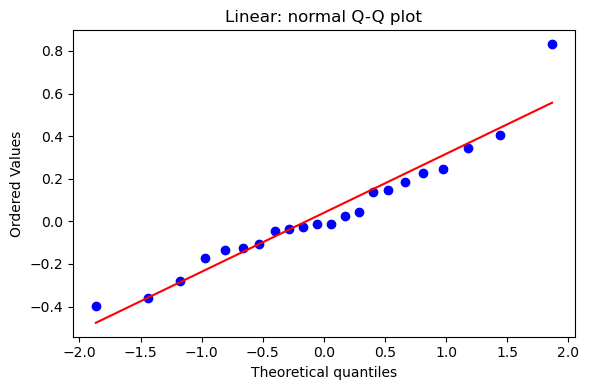

Model: SVM
Test MAE: 0.2218
Normality p-value: 0.00209289

SVM - statistic: 12.3384, p-value: 0.00209289


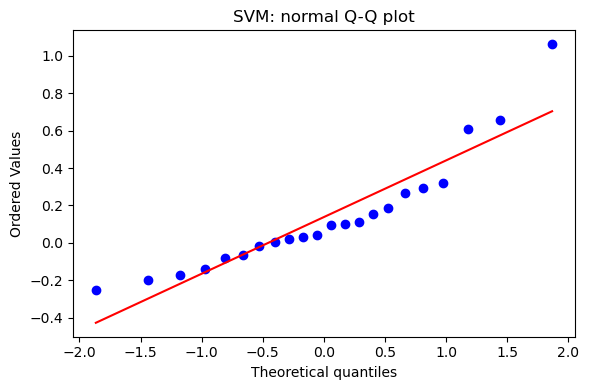

Model: Decision Tree
Test MAE: 0.2138
Normality p-value: 0.203755

Decision Tree - statistic: 3.1817, p-value: 0.203755


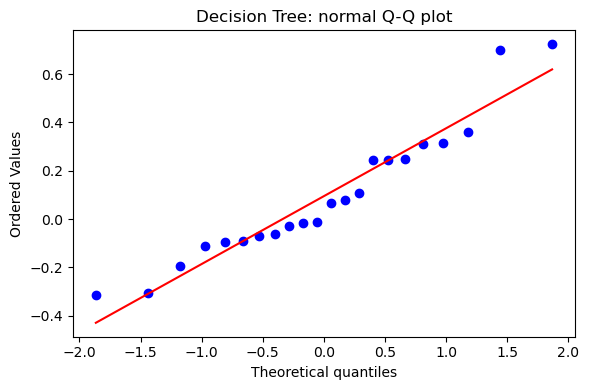

Model: Neural Network
Test MAE: 0.1534
Normality p-value: 0.686465

Neural Network - statistic: 0.7524, p-value: 0.686465


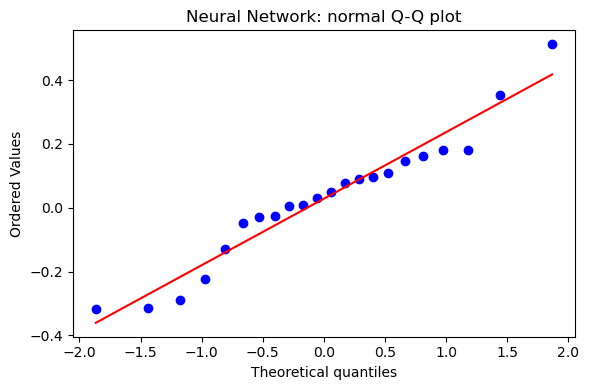

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.neural_network import MLPRegressor

df = pd.read_csv('mcs_ds_edited_iter_shuffled.csv')
X = df[['anchor_ratio', 'trans_range', 'node_density', 'iterations']]
y = df['ale']

# 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# standardize (fit on train only)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

models = {
    'Linear': LinearRegression(),
    'SVM': SVR(),
    'Decision Tree': DecisionTreeRegressor(max_depth=5, random_state=42),
    'Neural Network': MLPRegressor(max_iter=2000, random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    residuals = np.asarray(y_test).ravel() - preds

    mae = mean_absolute_error(y_test, preds)
    stat, p_value = stats.normaltest(residuals)

    print(f"Model: {name}")
    print(f"Test MAE: {mae:.4f}")
    print(f"Normality p-value: {p_value:.6g}\n")
    
    print(f"{name} - statistic: {stat:.4f}, p-value: {p_value:.6g}")
    fig, ax = plt.subplots(figsize=(6, 4))
    stats.probplot(residuals, dist="norm", plot=ax)
    ax.set_title(f"{name}: normal Q-Q plot")
    plt.tight_layout()
    plt.show()

In [2]:
data = load_breast_cancer()

X = data.data
y = data.target

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of features:", X.shape[1])
print("Target classes:", np.unique(y))

X shape: (569, 30)
y shape: (569,)
Number of features: 30
Target classes: [0 1]


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])

Training samples: 455
Test samples: 114


Standardize the features



In [4]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled[:5])

[[-1.07200079e+00 -6.58424598e-01 -1.08808010e+00 -9.39273639e-01
  -1.35939882e-01 -1.00871795e+00 -9.68358632e-01 -1.10203235e+00
   2.81062120e-01 -1.13231479e-01 -7.04860874e-01 -4.40938351e-01
  -7.43948977e-01 -6.29804931e-01  7.48061001e-04 -9.91572979e-01
  -6.93759567e-01 -9.83284458e-01 -5.91579010e-01 -4.28972052e-01
  -1.03409427e+00 -6.23497432e-01 -1.07077336e+00 -8.76534437e-01
  -1.69982346e-01 -1.03883630e+00 -1.07899452e+00 -1.35052668e+00
  -3.52658049e-01 -5.41380026e-01]
 [ 1.74874285e+00  6.65017334e-02  1.75115682e+00  1.74555856e+00
   1.27446827e+00  8.42288215e-01  1.51985232e+00  1.99466430e+00
  -2.93045055e-01 -3.20179716e-01  1.27567198e-01 -3.81382677e-01
   9.40746962e-02  3.17524379e-01  6.39656015e-01  8.73892616e-02
   7.08450758e-01  1.18215034e+00  4.26212305e-01  7.47970186e-02
   1.22834212e+00 -9.28334970e-02  1.18746742e+00  1.10438613e+00
   1.51700092e+00  2.49654896e-01  1.17859444e+00  1.54991557e+00
   1.91077868e-01 -1.73738602e-01]
 [-9.7

Baseline: scikit-learn Logistic Regression

This serves as the baseline comparison model requested in the assignment.

In [5]:
baseline_model = LogisticRegression(max_iter=1000)

baseline_model.fit(X_train_scaled, y_train)

baseline_predictions = baseline_model.predict(X_test_scaled)

baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

print(f"Sklearn Logistic Regression Accuracy: {baseline_accuracy:.4f}")

Sklearn Logistic Regression Accuracy: 0.9825


In [6]:
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_t = torch.tensor(y_train, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

print(X_train_t.shape)
print(y_train_t.shape)

torch.Size([455, 30])
torch.Size([455])


Custom Binary Cross-Entropy Loss


In [7]:
def binary_cross_entropy(y_true, y_pred):
    epsilon = 1e-7

    y_pred = torch.clamp(
        y_pred,
        epsilon,
        1 - epsilon
    )

    loss = -(
        y_true * torch.log(y_pred)
        +
        (1 - y_true) * torch.log(1 - y_pred)
    )

    return torch.mean(loss)

 Custom Logistic Regression



In [1]:
class CustomLogisticRegression(nn.Module):

    def __init__(self, num_features):
        super().__init__()

        self.w = nn.Parameter(
            torch.zeros(num_features)
        )

        self.b = nn.Parameter(
            torch.zeros(1)
        )

    def forward(self, X):
        z = X @ self.w + self.b
        probability = torch.sigmoid(z)
        return probability

NameError: name 'nn' is not defined

## Train the custom logistic regression model

Epoch    0 | Loss = 0.693147
Epoch  500 | Loss = 0.125909
Epoch 1000 | Loss = 0.098677
Epoch 1500 | Loss = 0.087027
Epoch 2000 | Loss = 0.080225
Epoch 2500 | Loss = 0.075650
Epoch 3000 | Loss = 0.072305
Epoch 3500 | Loss = 0.069723
Epoch 4000 | Loss = 0.067651
Epoch 4500 | Loss = 0.065938


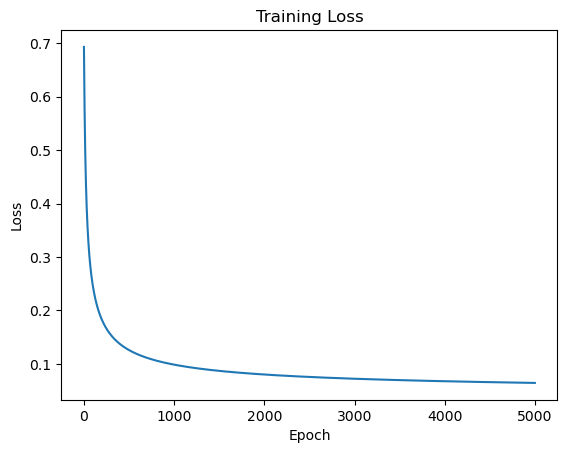

In [ ]:
import matplotlib.pyplot as plt
losses = []
logistic_model = CustomLogisticRegression(
    num_features=X_train_t.shape[1]
)

optimizer = torch.optim.SGD(
    logistic_model.parameters(),
    lr=0.01
)

num_epochs = 5000

for epoch in range(num_epochs):

    optimizer.zero_grad()

    predictions = logistic_model(X_train_t)

    loss = binary_cross_entropy(
        y_train_t,
        predictions
    )

    # Automatic differentiation
    loss.backward()
    losses.append(loss.item())

    # SGD parameter update
    optimizer.step()

    if epoch % 500 == 0:
        print(
            f"Epoch {epoch:4d} | Loss = {loss.item():.6f}"
        )


plt.plot(losses)
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

## Evaluate the custom logistic regression model

Predicted probabilities greater than or equal to 0.5 are classified as class 1.

In [10]:
with torch.no_grad():

    probabilities = logistic_model(X_test_t)

    logistic_predictions = (
        probabilities >= 0.5
    ).float()

    logistic_accuracy = (
        logistic_predictions == y_test_t
    ).float().mean().item()

print(f"Custom Logistic Regression Accuracy: {logistic_accuracy:.4f}")

Custom Logistic Regression Accuracy: 0.9737


Probit Regression


In [11]:
class ProbitRegression(nn.Module):

    def __init__(self, num_features):
        super().__init__()

        self.w = nn.Parameter(
            torch.zeros(num_features)
        )

        self.b = nn.Parameter(
            torch.zeros(1)
        )

        self.normal = torch.distributions.Normal(
            0.0,
            1.0
        )

    def forward(self, X):
        z = X @ self.w + self.b
        probability = self.normal.cdf(z)
        return probability

## Train the probit regression model

In [12]:
probit_model = ProbitRegression(
    num_features=X_train_t.shape[1]
)

optimizer_probit = torch.optim.SGD(
    probit_model.parameters(),
    lr=0.01
)

num_epochs = 5000

for epoch in range(num_epochs):

    optimizer_probit.zero_grad()

    predictions = probit_model(X_train_t)

    loss = binary_cross_entropy(
        y_train_t,
        predictions
    )

    loss.backward()

    optimizer_probit.step()

    if epoch % 500 == 0:
        print(
            f"Epoch {epoch:4d} | Loss = {loss.item():.6f}"
        )

Epoch    0 | Loss = 0.693147
Epoch  500 | Loss = 0.086099
Epoch 1000 | Loss = 0.072481
Epoch 1500 | Loss = 0.066638
Epoch 2000 | Loss = 0.063156
Epoch 2500 | Loss = 0.060751
Epoch 3000 | Loss = 0.058946
Epoch 3500 | Loss = 0.057519
Epoch 4000 | Loss = 0.056347
Epoch 4500 | Loss = 0.055358


## Evaluate the probit regression model

In [13]:
with torch.no_grad():

    probabilities = probit_model(X_test_t)

    probit_predictions = (
        probabilities >= 0.5
    ).float()

    probit_accuracy = (
        probit_predictions == y_test_t
    ).float().mean().item()

print(f"Probit Regression Accuracy: {probit_accuracy:.4f}")

Probit Regression Accuracy: 0.9737


# Final Comparison

In [14]:
print("----------------------------------------")
print("Final Accuracy Comparison")
print("----------------------------------------")

print(
    f"Sklearn Logistic Regression: "
    f"{baseline_accuracy:.4f}"
)

print(
    f"Custom Logistic Regression:  "
    f"{logistic_accuracy:.4f}"
)

print(
    f"Custom Probit Regression:    "
    f"{probit_accuracy:.4f}"
)

----------------------------------------
Final Accuracy Comparison
----------------------------------------
Sklearn Logistic Regression: 0.9825
Custom Logistic Regression:  0.9737
Custom Probit Regression:    0.9737


## Discussion

The scikit-learn logistic regression model provides the baseline test accuracy.

The custom logistic regression model uses the same general sigmoid-link idea, but its parameters are optimized manually using PyTorch's automatic differentiation system and SGD.

The probit regression model replaces the sigmoid link function with the standard normal CDF. Its parameters are also trained with SGD using the same binary cross-entropy objective.

You should compare the three reported test accuracies. If the custom models achieve accuracies close to the scikit-learn baseline, this indicates that both custom implementations are functioning successfully.

A possible write-up is:

> The custom logistic regression and probit regression models achieved test accuracies comparable to the scikit-learn logistic regression baseline. This shows that both the sigmoid and standard normal CDF can be used as link functions for binary classification on this dataset. Small differences in accuracy can arise from differences in optimization procedures, learning rate, convergence, and model implementation.

Regression:ALE

In [16]:
import pandas as pd

In [17]:
df_2=pd.read_csv("mcs_ds_edited_iter_shuffled.csv")

In [46]:
X=df_2.drop(columns=["ale",'sd_ale']).values
y=df_2['ale'].values
print(X[:5])
print("X shape:", X.shape)
print("y shape:", y.shape)

from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(X_train_scaled[:5])

print("Training samples:", X_train_scaled.shape[0])
print("Test samples:", X_test_scaled.shape[0])

[[ 30  15 200  40]
 [ 15  15 100  70]
 [ 30  15 100  50]
 [ 15  20 100  20]
 [ 30  15 100  40]]
X shape: (107, 4)
y shape: (107,)
[[-0.8961377  -0.34892633  0.52353599  2.06633874]
 [ 0.03278553  0.63969828  0.52353599 -0.40338884]
 [ 0.03278553  0.63969828 -0.86710649 -1.22663136]
 [ 1.5809909  -1.00800941 -0.86710649  2.06633874]
 [ 0.03278553  0.63969828 -0.86710649  0.00823243]]
Training samples: 85
Test samples: 22


BASELINEMODEL:LINEAR REGRESSION straight from Sklearn


In [58]:
from sklearn import linear_model
from sklearn.metrics import mean_absolute_error
baseline_model = linear_model.LinearRegression()
baseline_model.fit(X_train_scaled, y_train)
baseline_accuracy = baseline_model.score(X_test_scaled , y_test)
baseline_model_1 = linear_model.LinearRegression()
baseline_model_1.fit(X_train, y_train)
baseline_accuracy_1 = baseline_model_1.score(X_test, y_test)
print(f"Sklearn Linear Regression R^2 Score: {baseline_accuracy:.4f}")
print(f"Sklearn Linear Regression R^2 Score (Unscaled): {baseline_accuracy_1:.4f}") 
baseline_mae = mean_absolute_error(y_test, baseline_model.predict(X_test_scaled))
print(f"Sklearn Linear Regression MAE: {baseline_mae:.4f}")


Sklearn Linear Regression R^2 Score: 0.6292
Sklearn Linear Regression R^2 Score (Unscaled): 0.6292
Sklearn Linear Regression MAE: 0.1954


DEFINE Custom Model:
Define Linear Regression Model

In [43]:
class CustomLinearRegression(nn.Module):
    
    def __init__(self, num_features):
        super().__init__()

        self.w = nn.Parameter(
            torch.zeros(num_features)
        )

        self.b = nn.Parameter(
            torch.zeros(1)
        )

    def forward(self, X):
        return X @ self.w + self.b
    

Define Learning Objective (Squared Error)

In [44]:
class SquaredErrorLoss(nn.Module):
    
    def forward(self, y_true, y_pred):
        loss = (y_true - y_pred) ** 2
        return torch.mean(loss)

In [56]:
class StochasticGradientDescent:
    
    def __init__(self, model, loss_fn, learning_rate=0.01):
        self.model = model
        self.loss_fn = loss_fn
        self.learning_rate = learning_rate

    def step(self, X, y):
        # Zero ALL gradients safely
        self.model.zero_grad()

        # Forward pass
        predictions = self.model(X)
        loss = self.loss_fn(y, predictions)

        # Backward pass
        loss.backward()

        # Update parameters
        with torch.no_grad():
            for param in self.model.parameters():
                param.data -= self.learning_rate * param.grad

        return loss.item()

Custom Linear Regression Training:

In [60]:
# Convert ONCE before the loop
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)

custom_linear_model = CustomLinearRegression(num_features=X_train_scaled.shape[1])
custom_loss_fn = SquaredErrorLoss()
optimizer = StochasticGradientDescent(custom_linear_model, custom_loss_fn, learning_rate=0.01)

for epoch in range(1000):
    loss = optimizer.step(X_train_tensor, y_train_tensor)
    if epoch % 100 == 0:
        print(f"Epoch {epoch:4d} | Loss = {loss:.6f}")

print("Training complete.")
custom_linear_model_mae = mean_absolute_error(y_test, custom_linear_model(torch.tensor(X_test_scaled, dtype=torch.float32)).detach().numpy())
print(f"Custom Linear Regression MAE: {custom_linear_model_mae:.4f}")

Epoch    0 | Loss = 1.066105
Epoch  100 | Loss = 0.072861
Epoch  200 | Loss = 0.051572
Epoch  300 | Loss = 0.050669
Epoch  400 | Loss = 0.050591
Epoch  500 | Loss = 0.050583
Epoch  600 | Loss = 0.050582
Epoch  700 | Loss = 0.050582
Epoch  800 | Loss = 0.050582
Epoch  900 | Loss = 0.050582
Training complete.
Custom Linear Regression MAE: 0.1954


(b): t-distribution if residuals are not approximately normal


In [61]:
class StudentTLoss(nn.Module):
    def forward(self, y_true, y_pred):
        dist = torch.distributions.StudentT(df=5)
        return -dist.log_prob(y_true - y_pred).mean()

In [63]:
custom_t_model = CustomLinearRegression(num_features=X_train_scaled.shape[1])
custom_t_loss = StudentTLoss()
optimizer = StochasticGradientDescent(custom_t_model, custom_t_loss, learning_rate=0.01)

for epoch in range(1000):
    loss = optimizer.step(X_train_tensor, y_train_tensor)
    if epoch % 100 == 0:
        print(f"Epoch {epoch:4d} | Loss = {loss:.6f}")

print("Training complete.")
custom_t_model_mae = mean_absolute_error(y_test, custom_t_model(torch.tensor(X_test_scaled, dtype=torch.float32)).detach().numpy())
print(f"Custom Student T Regression MAE: {custom_t_model_mae:.4f}")


Epoch    0 | Loss = 1.516087
Epoch  100 | Loss = 1.071882
Epoch  200 | Loss = 1.007605
Epoch  300 | Loss = 0.999376
Epoch  400 | Loss = 0.998049
Epoch  500 | Loss = 0.997764
Epoch  600 | Loss = 0.997690
Epoch  700 | Loss = 0.997670
Epoch  800 | Loss = 0.997664
Epoch  900 | Loss = 0.997662
Training complete.
Custom Student T Regression MAE: 0.1941
